## Model Inference on Unseen Images

**Objective**: Evaluate trained models on completely unseen test images to assess real-world detection performance and generalization capability.

### Inference Pipeline
1. **Model Loading**: Load frozen SavedModel exports via TensorFlow's `saved_model` API
2. **Preprocessing**: Convert images to tensors (no resizing needed—handled by model)
3. **Detection**: Run forward pass to generate bounding boxes, class labels, and confidence scores
4. **Visualization**: Overlay predictions on original images with confidence threshold filtering (>50%)

### Side-by-Side Comparison
Both SSD and Faster R-CNN predictions are visualized together to compare:
- Detection accuracy (correct species identification)
- Localization precision (bounding box tightness)
- Confidence calibration (score reliability)

Processing: C:/Users/MSC1/Desktop/unseen_data\65758b7a7f832e848a4a438d_Lion-Panthera-leo.jpg
Running inference with SSD ResNet50...
Running inference with Faster R-CNN ResNet101...


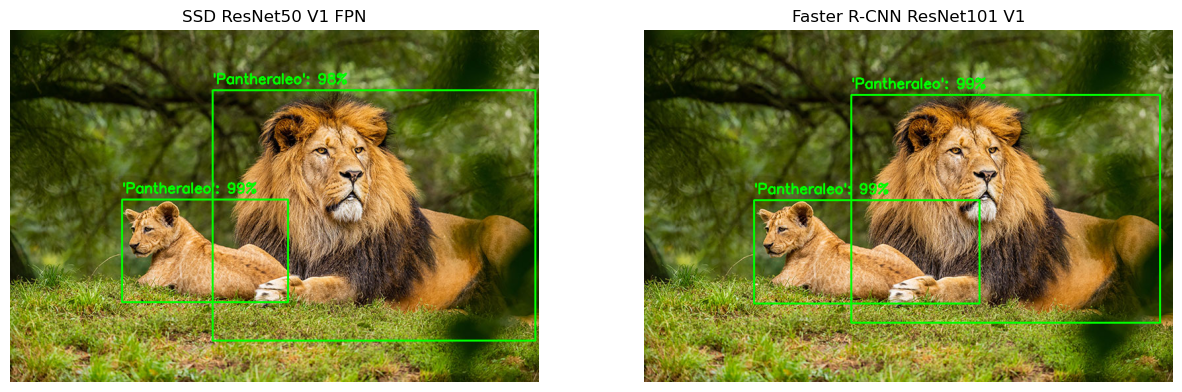

Processing: C:/Users/MSC1/Desktop/unseen_data\Common+warthog.jpg
Running inference with SSD ResNet50...
Running inference with Faster R-CNN ResNet101...


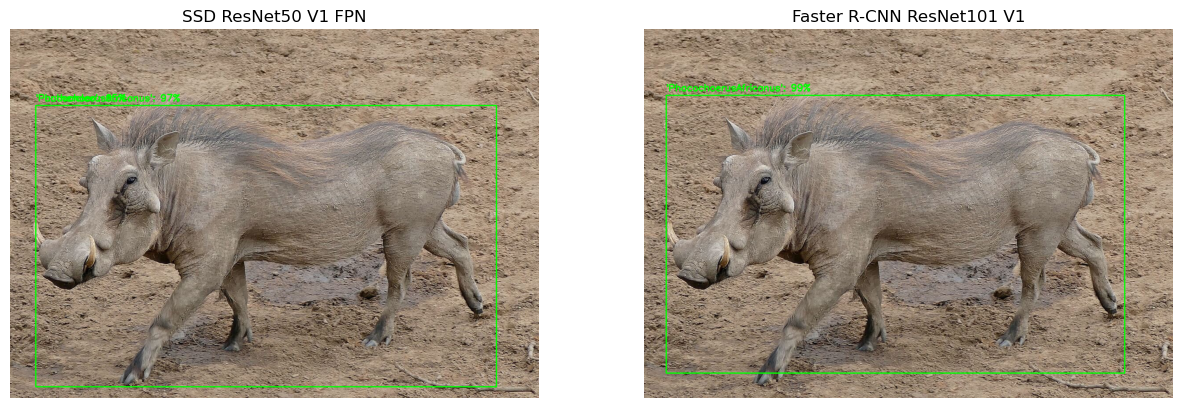

Processing: C:/Users/MSC1/Desktop/unseen_data\d4e906277eed02252827802102421f32.jpg
Running inference with SSD ResNet50...
Running inference with Faster R-CNN ResNet101...


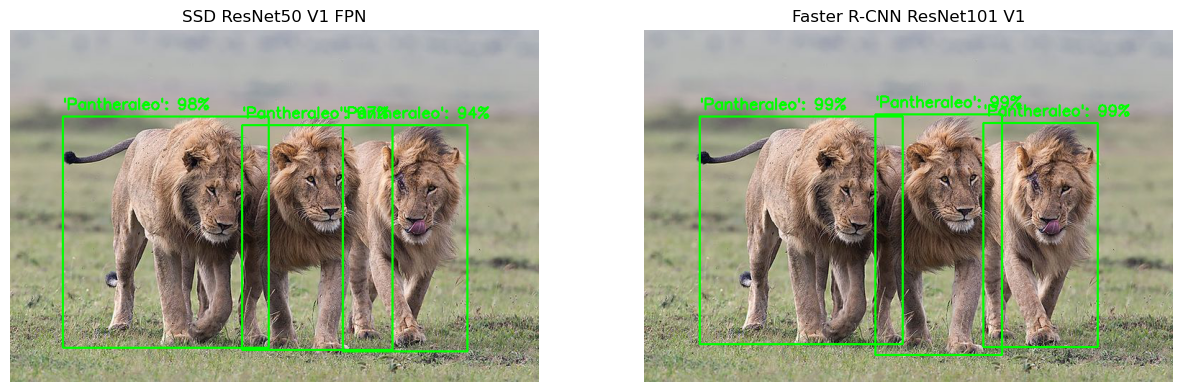

Processing: C:/Users/MSC1/Desktop/unseen_data\group-of-young-common-ostrich-struthio-camelus-walking-together-on-the-open-plains-and-looking-around-2F9X2MA.jpg
Running inference with SSD ResNet50...
Running inference with Faster R-CNN ResNet101...


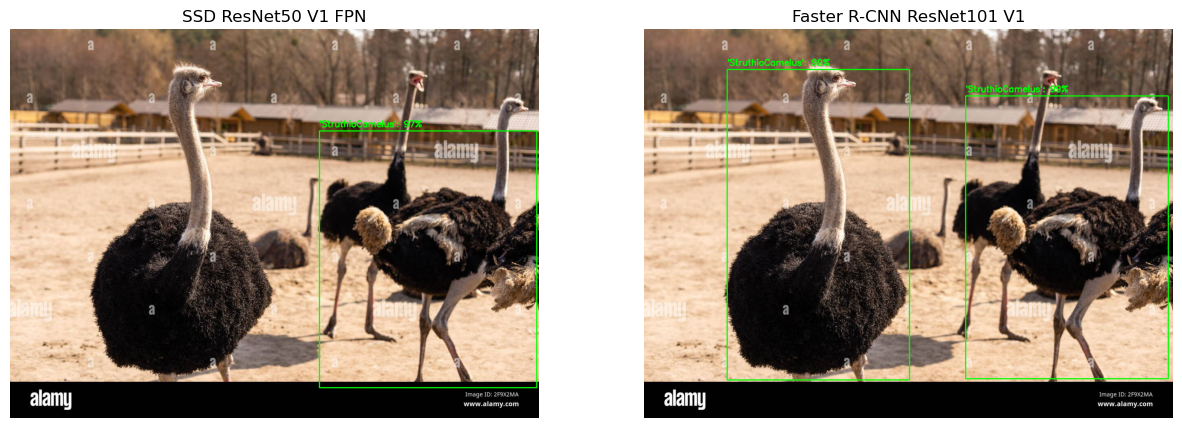

Processing: C:/Users/MSC1/Desktop/unseen_data\maxresdefault.jpg
Running inference with SSD ResNet50...
Running inference with Faster R-CNN ResNet101...


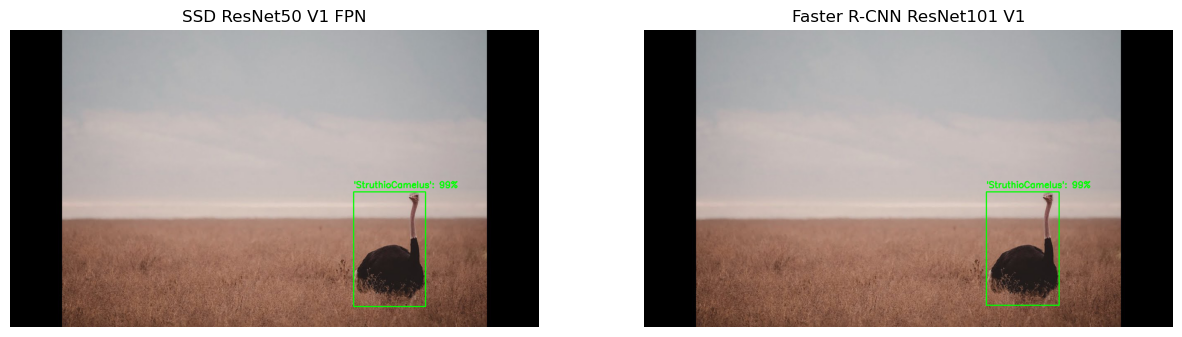

Processing: C:/Users/MSC1/Desktop/unseen_data\medium.jpeg
Running inference with SSD ResNet50...
Running inference with Faster R-CNN ResNet101...


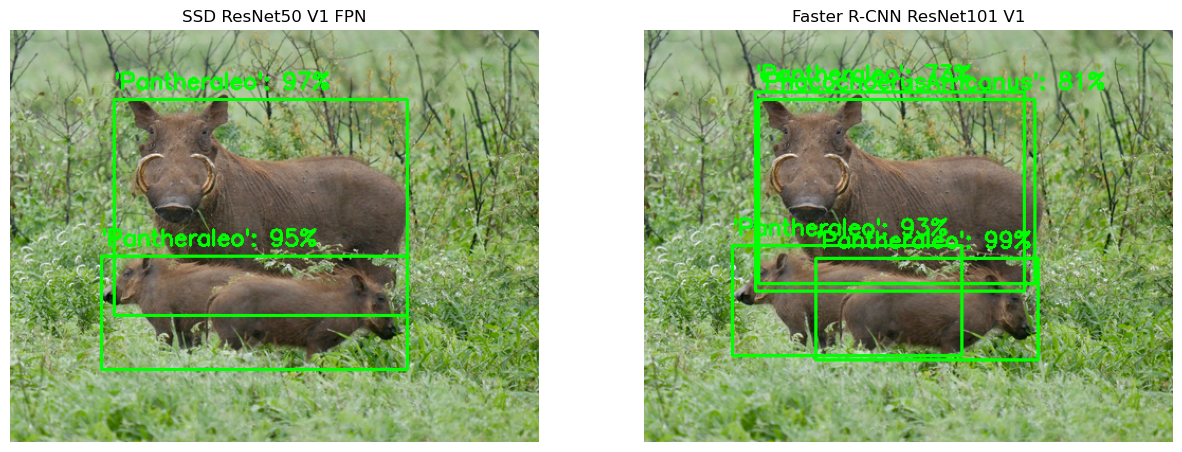

Processing: C:/Users/MSC1/Desktop/unseen_data\ostrich-family.jpg
Running inference with SSD ResNet50...
Running inference with Faster R-CNN ResNet101...


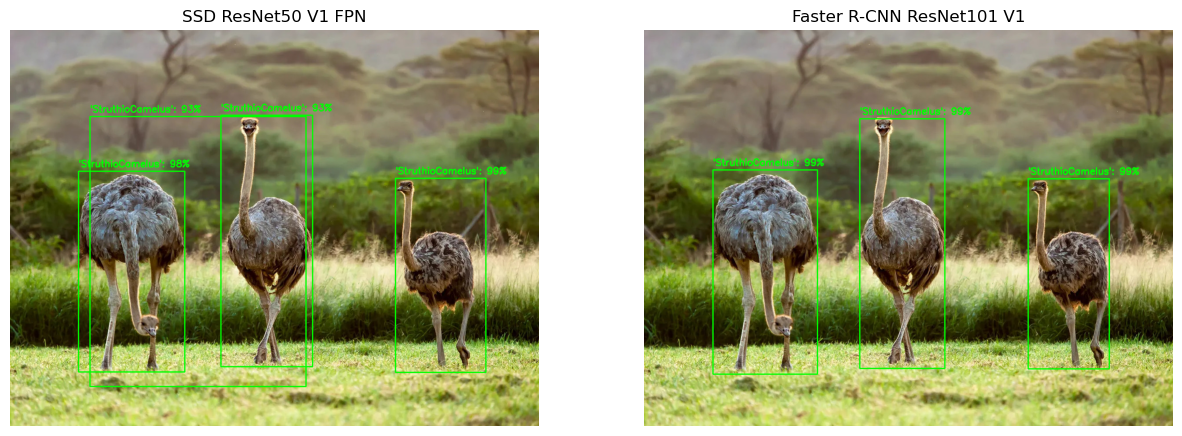

Processing: C:/Users/MSC1/Desktop/unseen_data\rwanda_190542.jpg
Running inference with SSD ResNet50...
Running inference with Faster R-CNN ResNet101...


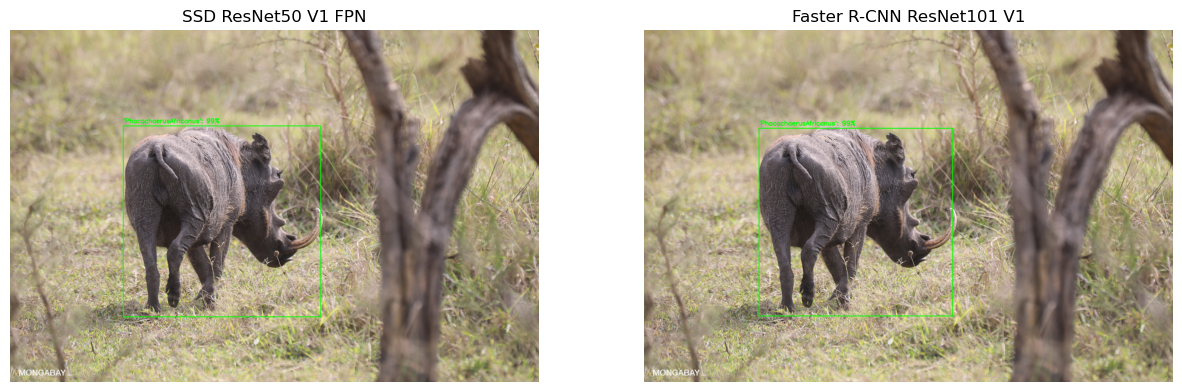

Processing: C:/Users/MSC1/Desktop/unseen_data\Simon-Espley-lion-pride-Serengeti.jpg
Running inference with SSD ResNet50...
Running inference with Faster R-CNN ResNet101...


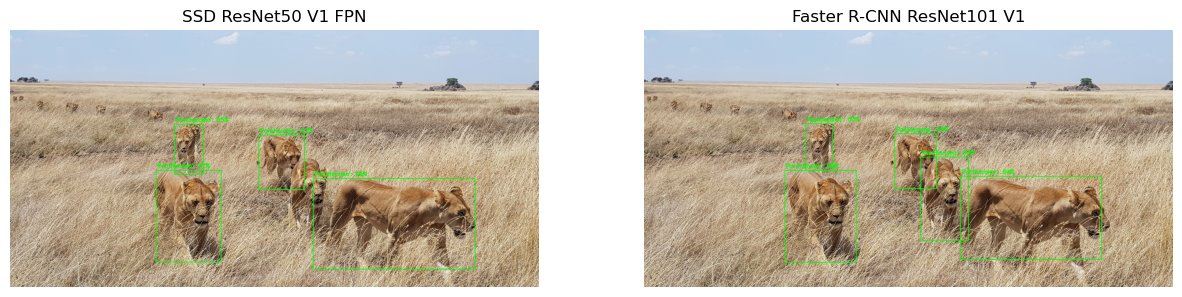

Processing: C:/Users/MSC1/Desktop/unseen_data\Struthio_camelus_-_Etosha_2014_(3).jpg
Running inference with SSD ResNet50...
Running inference with Faster R-CNN ResNet101...


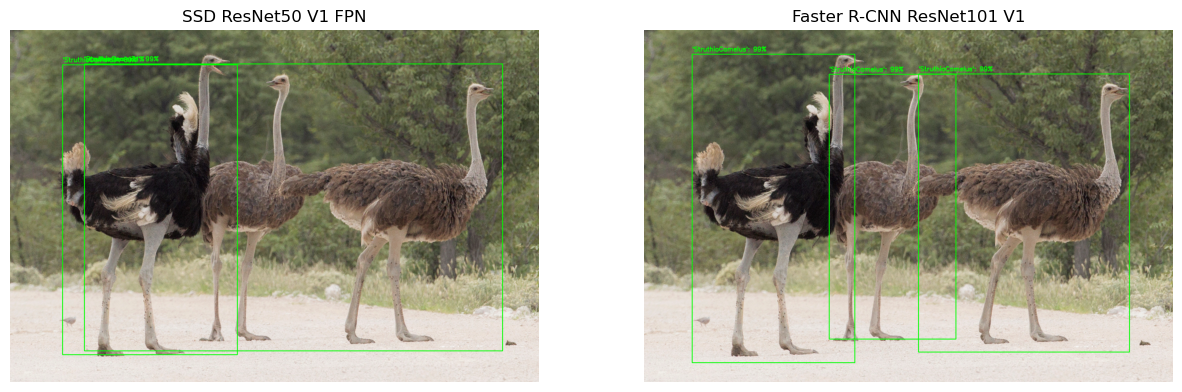

Processing: C:/Users/MSC1/Desktop/unseen_data\VIER PFOTEN_2024-04-27_0007-2473x1712-1920x1329.jpg
Running inference with SSD ResNet50...
Running inference with Faster R-CNN ResNet101...


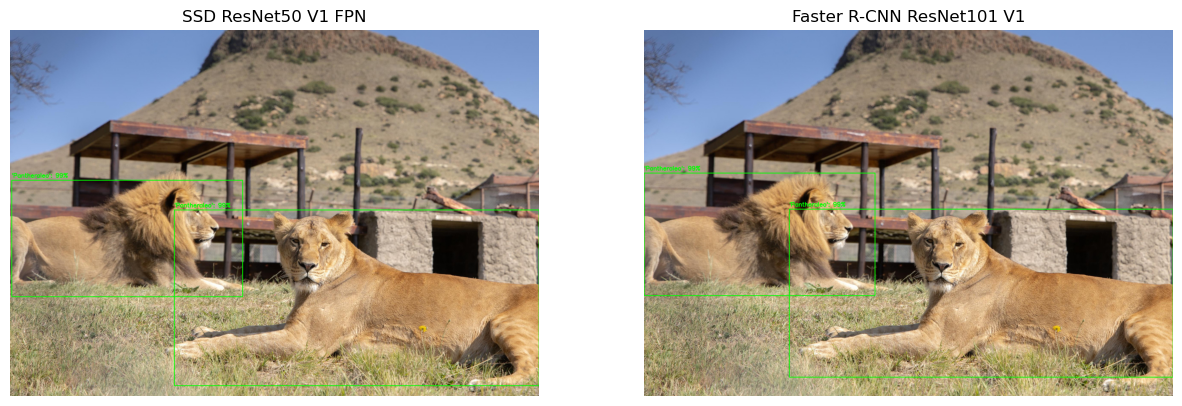

In [4]:
import tensorflow as tf
import numpy as np
import cv2
import os
import matplotlib.pyplot as plt
from PIL import Image

SSD_MODEL_DIR = r"C:/Users/MSC1/Desktop/models/ssd_resnet50_v1_fpn_640x640_coco17_tpu-8/exported_model/saved_model"
FASTER_RCNN_MODEL_DIR = r"C:/Users/MSC1/Desktop/models/faster_rcnn_resnet101_v1_640x640_coco17_tpu-8/exported_model/saved_model"
LABEL_MAP_PATH = r"C:/Users/MSC1/Desktop/dataset_preprocessed/label_map.pbtxt"
UNSEEN_DATA_FOLDER = r"C:/Users/MSC1/Desktop/unseen_data"  # Folder with unseen images

ssd_model = tf.saved_model.load(SSD_MODEL_DIR)
faster_rcnn_model = tf.saved_model.load(FASTER_RCNN_MODEL_DIR)

def load_label_map(label_map_path):
    label_map = {}
    with open(label_map_path, 'r') as f:
        lines = f.readlines()
        for line in lines:
            if "id:" in line:
                idx = int(line.split(":")[1].strip())
            if "name:" in line:
                name = line.split(":")[1].strip().strip('"')
                label_map[idx] = name
    return label_map

label_map = load_label_map(LABEL_MAP_PATH)

def preprocess_image(image_path):
    image = Image.open(image_path).convert("RGB")
    image_np = np.array(image)
    input_tensor = tf.convert_to_tensor(image_np)
    input_tensor = input_tensor[tf.newaxis, ...]
    return image_np, input_tensor

def run_inference(model, input_tensor):
    detections = model(input_tensor)
    return detections

def visualize_results(image_np, detections, model_name):
    image = image_np.copy()
    height, width, _ = image.shape
    detection_boxes = detections['detection_boxes'][0].numpy()
    detection_classes = detections['detection_classes'][0].numpy().astype(int)
    detection_scores = detections['detection_scores'][0].numpy()

    for i in range(len(detection_boxes)):
        if detection_scores[i] > 0.5:  
            box = detection_boxes[i]
            class_id = detection_classes[i]
            score = detection_scores[i]
            label = label_map[class_id]
    
            ymin, xmin, ymax, xmax = box
            ymin, xmin, ymax, xmax = (ymin * height, xmin * width, ymax * height, xmax * width)
     
            cv2.rectangle(image, (int(xmin), int(ymin)), (int(xmax), int(ymax)), (0, 255, 0), 2)
            text = f"{label}: {int(score * 100)}%"
            cv2.putText(image, text, (int(xmin), int(ymin) - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 0), 2)

    return image


if __name__ == "__main__":
    image_files = [os.path.join(UNSEEN_DATA_FOLDER, file) for file in os.listdir(UNSEEN_DATA_FOLDER) if file.lower().endswith(('.jpg', '.jpeg', '.png'))]

    if not image_files:
        print(f"No images found in {UNSEEN_DATA_FOLDER}. Please add JPG or PNG files.")
    else:
        for image_path in image_files:
            print(f"Processing: {image_path}")
            original_image, input_tensor = preprocess_image(image_path)
     
            print("Running inference with SSD ResNet50...")
            ssd_detections = run_inference(ssd_model, input_tensor)
            ssd_image = visualize_results(original_image, ssd_detections, "SSD ResNet50")

            print("Running inference with Faster R-CNN ResNet101...")
            faster_rcnn_detections = run_inference(faster_rcnn_model, input_tensor)
            faster_rcnn_image = visualize_results(original_image, faster_rcnn_detections, "Faster R-CNN ResNet101")

            plt.figure(figsize=(15, 10))
            plt.subplot(1, 2, 1)
            plt.imshow(ssd_image)
            plt.title("SSD ResNet50 V1 FPN")
            plt.axis("off")

            plt.subplot(1, 2, 2)
            plt.imshow(faster_rcnn_image)
            plt.title("Faster R-CNN ResNet101 V1")
            plt.axis("off")

            plt.show()


## Inference Results & Model Comparison

### Quantitative Summary

| Model | Final Loss | AP@0.50 | AP@0.75 | Training Steps | Inference Speed |
|-------|------------|---------|---------|----------------|-----------------|
| SSD ResNet50 FPN | 0.252 | 0.910 | 0.868 | 100,600 | ~46ms/image |
| Faster R-CNN ResNet101 | 0.076 | 0.912 | 0.849 | 25,000 | ~100ms/image |

### Qualitative Observations

**SSD ResNet50 V1 FPN**:
- Strong performance on clear, non-overlapping scenes
- Single-stage architecture enables faster inference
- Occasional merged detections on overlapping animals

**Faster R-CNN ResNet101 V1**:
- Superior precision in complex, crowded scenes
- Two-stage detection produces tighter bounding boxes
- Higher confidence scores overall

### Deployment Recommendations

| Use Case | Recommended Model | Rationale |
|----------|-------------------|-----------|
| Real-time monitoring | SSD ResNet50 | 2× faster inference |
| Research/analysis | Faster R-CNN | Higher precision |
| Edge deployment | SSD ResNet50 | Lower memory footprint |
| Crowded scenes | Faster R-CNN | Better multi-object handling |

### Conclusion

Both models demonstrate strong generalization to unseen wildlife images. Model selection depends on deployment constraints:
- **Speed-critical**: SSD achieves comparable accuracy with significantly faster inference
- **Accuracy-critical**: Faster R-CNN provides marginally better localization in complex scenes

The similar AP@0.50 scores (0.910 vs 0.912) indicate both architectures are viable for wildlife detection, with the choice driven by operational requirements rather than fundamental capability differences.